# Chapitre 12 - Exercices 12.1 à 12.5

* 12.1 : équivalence entre la forme « perte charnière + pénalité » (12.25) et le problème
  quadratique (12.8) ;
* 12.2 : la forme à noyau (12.29) est (12.25) pour un noyau particulier ;
* 12.3 : régression à noyau quand on ne pénalise pas la constante ;
* 12.4 : distances dans l'espace des variables canoniques de la LDA ;
* 12.5 : classification de phonèmes par prototypes lisses (k-moyennes sur une base de
  splines).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch12_svm import (SVMClassifier, hinge_loss, rbf_kernel, polynomial_kernel,
                          poly2_features, LDA, kmeans, natural_spline_basis)
set_style()

## Exercice 12.1 : Équivalence de (12.25) et (12.8)

**Énoncé.** Montrer que les critères (12.25) et (12.8) sont équivalents, c'est-à-dire que

$$\text{(12.8)}\quad \min_{\beta,\beta_0,\xi}\ \tfrac12\|\beta\|^2 + C\sum_i\xi_i\ \ \text{s.c.}\ \ \xi_i\ge0,\ y_i(x_i^T\beta+\beta_0)\ge1-\xi_i$$

et

$$\text{(12.25)}\quad \min_{\beta,\beta_0}\ \sum_i\left[1 - y_i(x_i^T\beta + \beta_0)\right]_+ + \frac\lambda2\|\beta\|^2$$

ont les mêmes solutions $(\hat\beta,\hat\beta_0)$ lorsque $\lambda = 1/C$.

**Solution.** *Étape 1 : élimination des variables d'écart.* Fixons $(\beta,\beta_0)$ et
notons $m_i = y_i(x_i^T\beta + \beta_0)$. Les contraintes sur $\xi_i$ sont $\xi_i\ge0$ et
$\xi_i \ge 1 - m_i$, soit $\xi_i \ge \max(0, 1-m_i) = [1-m_i]_+$. Comme l'objectif est
strictement croissant en chaque $\xi_i$ (coefficient $C > 0$), le meilleur choix est la plus
petite valeur admissible : $\xi_i = [1 - m_i]_+$.

*Étape 2 : problème réduit.* Minimiser (12.8) revient donc à minimiser, en $(\beta,\beta_0)$
seulement,

$$\Phi(\beta,\beta_0) = \tfrac12\|\beta\|^2 + C\sum_i[1-m_i]_+ .$$

En effet, si $(\beta^\star,\beta_0^\star,\xi^\star)$ minimise (12.8), alors pour tout
$(\beta,\beta_0)$ : $\Phi(\beta^\star,\beta_0^\star)\le$ valeur de (12.8) en
$(\beta^\star,\beta_0^\star,\xi^\star)\le$ valeur de (12.8) en $(\beta,\beta_0,[1-m]_+) = \Phi(\beta,\beta_0)$.
Réciproquement, un minimiseur de $\Phi$ complété par $\xi_i = [1-m_i]_+$ minimise (12.8).

*Étape 3 : changement d'échelle.* Multiplier une fonction par la constante $\lambda = 1/C > 0$
ne change pas ses minimiseurs :

$$\lambda\,\Phi(\beta,\beta_0) = \sum_i[1 - y_i(x_i^T\beta+\beta_0)]_+ + \frac\lambda2\|\beta\|^2,$$

qui est exactement (12.25). Les deux problèmes ont donc les mêmes solutions, et la valeur
optimale de (12.25) vaut $\lambda$ fois celle de (12.8). $\square$

**Vérification numérique.** On résout (12.25) directement, avec un optimiseur générique
(`scipy.optimize.minimize`, méthode SLSQP) appliqué à la forme « épigraphe » sans le terme
quadratique en $\xi$, et on compare au SVM obtenu par le dual.

In [2]:
rng = np.random.RandomState(0)
X = np.vstack([rng.randn(25, 2) + [1, 1], rng.randn(25, 2) - [1, 1]])
y = np.r_[np.ones(25), -np.ones(25)]
C = 0.5
lam = 1 / C

def crit_1225(theta):
    beta, beta0 = theta[:2], theta[2]
    return hinge_loss(y * (X @ beta + beta0)).sum() + lam / 2 * beta @ beta

# (12.25) n'est pas dérivable : on passe par les écarts xi pour SLSQP
N = len(y)
obj = lambda v: v[3:].sum() + lam / 2 * v[:2] @ v[:2]
cons = [{"type": "ineq", "fun": lambda v: v[3:]},
        {"type": "ineq", "fun": lambda v: y * (X @ v[:2] + v[2]) - 1 + v[3:]}]
sol = minimize(obj, np.r_[0, 0, 0, np.ones(N)], constraints=cons, method="SLSQP",
               options={"maxiter": 500, "ftol": 1e-12})
svm = SVMClassifier(C=C, kernel="linear").fit(X, y)
print("solution directe (12.25)  : beta =", sol.x[:2].round(5), " beta0 = %.5f" % sol.x[2])
print("SVM via le dual (12.8)    : beta =", svm.coef_.round(5), " beta0 = %.5f" % svm.b_)
print("critère (12.25) : %.6f  ;  lambda x critère (12.8) : %.6f"
      % (crit_1225(np.r_[svm.coef_, svm.b_]), lam * svm.primal_objective()))

solution directe (12.25)  : beta = [0.78548 0.87657]  beta0 = -0.09282
SVM via le dual (12.8)    : beta = [0.78548 0.87657]  beta0 = -0.09282
critère (12.25) : 10.029449  ;  lambda x critère (12.8) : 10.029449


Le critère (12.25) est convexe et minimal en la solution du SVM : traçons-le le long de
quelques directions aléatoires issues de $(\hat\beta, \hat\beta_0)$.

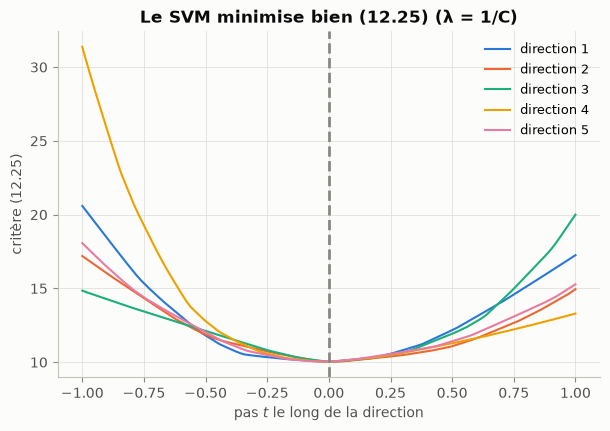

In [3]:
theta_hat = np.r_[svm.coef_, svm.b_]
tgrid = np.linspace(-1, 1, 201)
fig, ax = plt.subplots(figsize=(7, 4.5))
for k in range(5):
    d = rng.randn(3); d /= np.linalg.norm(d)
    ax.plot(tgrid, [crit_1225(theta_hat + t * d) for t in tgrid], color=COLORS[k], lw=1.5,
            label="direction %d" % (k + 1))
ax.axvline(0, color=GRAY, ls="--")
ax.set_xlabel("pas $t$ le long de la direction"); ax.set_ylabel("critère (12.25)")
ax.set_title("Le SVM minimise bien (12.25) (λ = 1/C)")
ax.legend()
plt.show()

> **À retenir.** Les variables d'écart optimales sont $\xi_i = [1 - y_if(x_i)]_+$ : le SVM est
> un problème « perte charnière + pénalité ridge », avec $\lambda = 1/C$.

## Exercice 12.2 : La forme à noyau (12.29)

**Énoncé.** Montrer que la solution de

$$\text{(12.29)}\quad \min_{\beta_0,\alpha}\ \sum_i\left(1 - y_if(x_i)\right)_+ + \frac\lambda2\alpha^T\mathbf K\alpha,\qquad f(x) = \beta_0 + \sum_{i}\alpha_iK(x,x_i),$$

est la même que celle de (12.25) pour un noyau particulier.

**Rappels.** Dans (12.25), $f(x) = h(x)^T\beta + \beta_0$ avec un vecteur de fonctions de base
$h(x)\in\mathbb R^M$. Notons $H$ la matrice $N\times M$ de lignes $h(x_i)^T$. On choisit le
noyau **associé à $h$** : $K(x,x') = \langle h(x), h(x')\rangle$, de sorte que
$\mathbf K = HH^T$.

**Solution.** *Étape 1 : décomposition de $\beta$.* Tout $\beta\in\mathbb R^M$ s'écrit de
façon unique $\beta = H^T\alpha + \beta_\perp$, où $H^T\alpha$ est la projection orthogonale
de $\beta$ sur le sous-espace engendré par les $h(x_i)$ et $\beta_\perp$ lui est orthogonal,
c'est-à-dire $H\beta_\perp = 0$ ($h(x_i)^T\beta_\perp = 0$ pour tout $i$).

*Étape 2 : $\beta_\perp = 0$ à l'optimum.* Aux points d'apprentissage,
$f(x_i) = h(x_i)^T H^T\alpha + h(x_i)^T\beta_\perp + \beta_0 = (HH^T\alpha)_i + \beta_0$ : la
perte ne dépend pas de $\beta_\perp$. Par Pythagore,
$\|\beta\|^2 = \|H^T\alpha\|^2 + \|\beta_\perp\|^2$. Remplacer $\beta_\perp$ par 0 diminue donc
strictement le critère si $\beta_\perp\neq0$ : à l'optimum, $\beta = H^T\alpha$.

*Étape 3 : réécriture.* Avec $\beta = H^T\alpha = \sum_i\alpha_ih(x_i)$ :

* $f(x) = h(x)^T H^T\alpha + \beta_0 = \sum_i\alpha_i\langle h(x), h(x_i)\rangle + \beta_0 = \beta_0 + \sum_i\alpha_iK(x,x_i)$ ;
* $\|\beta\|^2 = \alpha^THH^T\alpha = \alpha^T\mathbf K\alpha$.

Le critère (12.25) devient exactement (12.29). $\square$

**Lien avec le dual.** Par (12.10), $\beta = \sum_i\hat\alpha_i^{\text{dual}}y_ih(x_i)$ avec
$C = 1/\lambda$ : on s'attend donc à $\alpha_i = \hat\alpha_i^{\text{dual}}y_i$.

**Vérification numérique** avec le noyau radial ($M = \infty$ : seule la forme (12.29) est
calculable). On résout (12.29) par SLSQP (variables $\beta_0$, $\alpha$, écarts $\xi$) et on
compare à notre SVM.

In [ ]:
Xs, ys = X[::2], y[::2]          # 25 points pour garder un problème petit
Ks = rbf_kernel(Xs, Xs, 0.5)
n = len(ys)
lam2 = 1.0
obj2 = lambda v: v[1 + n:].sum() + lam2 / 2 * v[1:1 + n] @ Ks @ v[1:1 + n]
cons2 = [{"type": "ineq", "fun": lambda v: v[1 + n:]},
         {"type": "ineq", "fun": lambda v: ys * (v[0] + Ks @ v[1:1 + n]) - 1 + v[1 + n:]}]
sol2 = minimize(obj2, np.r_[0, np.zeros(n), np.ones(n)], constraints=cons2, method="SLSQP",
                options={"maxiter": 1000, "ftol": 1e-12})
svm2 = SVMClassifier(C=1 / lam2, kernel="rbf", gamma=0.5).fit(Xs, ys)
print("beta0 : (12.29) %.4f   SVM %.4f" % (sol2.x[0], svm2.b_))
print("écart max | alpha_(12.29) - alpha_dual * y | = %.2e" % np.abs(sol2.x[1:1 + n] - svm2.alpha_ * ys).max())
Zg = rng.randn(200, 2) * 1.5
f_1229 = sol2.x[0] + rbf_kernel(Zg, Xs, 0.5) @ sol2.x[1:1 + n]
print("écart max des fonctions f sur 200 points : %.2e" % np.abs(f_1229 - svm2.decision_function(Zg)).max())

> **À retenir.** Pour $K(x,x') = \langle h(x),h(x')\rangle$, la solution de (12.25) vit dans
> l'espace engendré par les $h(x_i)$ ; (12.29) en est la paramétrisation par $\alpha$, avec la
> pénalité $\|\beta\|^2 = \alpha^T\mathbf K\alpha$.

## Exercice 12.3 : Ne pas pénaliser la constante

**Énoncé.** On modifie (12.43) en ne pénalisant pas la constante :

$$\min_{\beta_0,\beta}\ H(\beta,\beta_0) = \sum_{i=1}^NV(y_i - f(x_i)) + \frac\lambda2\sum_{m=1}^M\beta_m^2,\qquad f(x) = \beta_0 + \sum_m\beta_mh_m(x),$$

où $\beta_0$ est libre (non pénalisé). Formuler le problème et caractériser sa solution.

**Solution (perte $V$ dérivable et convexe).** Notons $r_i = y_i - f(x_i)$ les résidus.
Les conditions d'optimalité s'obtiennent en annulant les dérivées partielles :

* par rapport à $\beta_m$ : $-\sum_iV'(r_i)h_m(x_i) + \lambda\beta_m = 0$, d'où
  $\hat\beta = \frac1\lambda\sum_iV'(r_i)\,h(x_i)$ ;
* par rapport à $\beta_0$ : $-\sum_iV'(r_i) = 0$.

En posant $\hat a_i = V'(r_i)/\lambda$, on obtient la **représentation**

$$\hat f(x) = \hat\beta_0 + \sum_{i=1}^N\hat a_iK(x,x_i),\qquad K(x,x') = \sum_mh_m(x)h_m(x'),\qquad \sum_{i=1}^N\hat a_i = 0.$$

La seule différence avec (12.44) est la **contrainte $\sum_i\hat a_i = 0$** (et le terme
$\hat\beta_0$). C'est exactement la contrainte $\sum_i(\alpha_i^* - \alpha_i) = 0$ du SVM de
régression (12.41), où $V = V_\varepsilon$ et $\beta_0$ n'est pas pénalisé.

**Cas de la perte quadratique $V(r) = r^2$.** Alors $V'(r) = 2r$, donc $\hat a = 2r/\lambda$,
soit $r = \frac\lambda2\hat a$. Comme $r = y - \hat\beta_0\mathbf 1 - \mathbf K\hat a$, on
obtient le système linéaire « bordé » de taille $N+1$ :

$$\begin{pmatrix}\mathbf K + \frac\lambda2I & \mathbf 1\\ \mathbf 1^T & 0\end{pmatrix}\begin{pmatrix}\hat a\\ \hat\beta_0\end{pmatrix} = \begin{pmatrix}y\\0\end{pmatrix}.$$

Avec $M_\lambda = \mathbf K + \frac\lambda2 I$ (inversible car $\mathbf K$ est semi-définie
positive), la première ligne donne $\hat a = M_\lambda^{-1}(y - \hat\beta_0\mathbf 1)$ et la
contrainte $\mathbf 1^T\hat a = 0$ donne
$\hat\beta_0 = \dfrac{\mathbf 1^TM_\lambda^{-1}y}{\mathbf 1^TM_\lambda^{-1}\mathbf 1}$ : une
moyenne pondérée des $y_i$.

**Vérification.** Avec $h(x) = (\sqrt2x_j, x_j^2, \sqrt2x_jx_k)$ (le plongement du noyau
$(1+\langle x,x'\rangle)^2$ privé de sa constante), $K(x,x') = (1+\langle x,x'\rangle)^2 - 1$.
On compare la solution du système bordé à la solution directe dans l'espace des $h$.

In [ ]:
rng = np.random.RandomState(1)
Xr = rng.randn(40, 2)
yr = 10 + Xr[:, 0] ** 2 - Xr[:, 1] + 0.3 * rng.randn(40)       # réponse décalée de +10
lam3 = 4.0
Hm = poly2_features(Xr)[:, 1:]                       # sans la colonne constante
Kr = Hm @ Hm.T
np.testing.assert_allclose(Kr, polynomial_kernel(Xr, Xr, 2) - 1, atol=1e-10)
# (i) noyau, système bordé
Mb = np.block([[Kr + lam3 / 2 * np.eye(40), np.ones((40, 1))], [np.ones((1, 40)), np.zeros((1, 1))]])
sol3 = np.linalg.solve(Mb, np.r_[yr, 0])
a_hat, b0_hat = sol3[:40], sol3[40]
# (ii) directement dans l'espace des h : moindres carrés + ridge sans pénaliser la constante
Ha = np.column_stack([np.ones(40), Hm])
P = np.eye(Ha.shape[1]); P[0, 0] = 0
coef = np.linalg.solve(Ha.T @ Ha + lam3 / 2 * P, Ha.T @ yr)
print("beta0 : noyau %.6f   direct %.6f" % (b0_hat, coef[0]))
print("somme des a_i = %.2e" % a_hat.sum())
print("écart max des ajustements : %.2e" % np.abs(b0_hat + Kr @ a_hat - Ha @ coef).max())